# Demo 3｜双边市场干扰与分流方案

决策问题：司机激励如何影响共享供给下的订单？本 notebook 用简化的潜在结果模型说明干扰造成的偏差与设计权衡，不拟合真实派单机制。

**数据声明**：以下均为固定随机种子生成的模拟数据，不代表真实滴滴业务效果。图中的英文标签用于避免本地中文字体依赖。

## 机制与目标量

模拟 12 区域、每区 100 笔订单。结果 = 基线 + 直接激励效应 0.6 + 区域平均激励暴露的溢出效应。目标是全量上线相对全量不上的效果 `direct + spillover`。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')
rng = np.random.default_rng(20261028)
from scipy.stats import norm
G=12;m=100;direct=.6
def simulate(design,spill,rng):
    if design=='order':z=rng.binomial(1,.5,(G,m))
    elif design=='region':z=np.repeat(rng.binomial(1,.5,(G,1)),m,axis=1)
    else:
        z=np.repeat(rng.binomial(1,.5,(G,1)),m,axis=1)
    exposure=z.mean(axis=1,keepdims=True)
    if design=='switch':exposure=.75*exposure+.25*np.roll(exposure,1,axis=0)
    y=8+direct*z+spill*exposure+rng.normal(0,1,(G,1))+rng.normal(0,.7,(G,m))
    return y[z==1].mean()-y[z==0].mean() if z.min()!=z.max() else np.nan
print('Full rollout effect at spillover=0.8:',direct+.8)

Full rollout effect at spillover=0.8: 1.4


## 随机化比较与偏差

订单级分流让处理和对照共享供给，估计值更接近直接效应而非全量上线效果。区域级设计识别更多区域暴露效应，但区域数少时方差更大。时间切换以区域时间块示意，滞后供给会削弱隔离。

    spillover  design   mean    std   bias
0         0.0   order  0.591  0.069 -0.009
1         0.0  region  0.558  0.594 -0.042
2         0.0  switch  0.615  0.608  0.015
3         0.4   order  0.600  0.069 -0.400
4         0.4  region  0.961  0.603 -0.039
5         0.4  switch  0.953  0.612 -0.047
6         0.8   order  0.615  0.074 -0.785
7         0.8  region  1.464  0.580  0.064
8         0.8  switch  1.232  0.622 -0.168
9         1.2   order  0.617  0.065 -1.183
10        1.2  region  1.795  0.665 -0.005
11        1.2  switch  1.503  0.577 -0.297


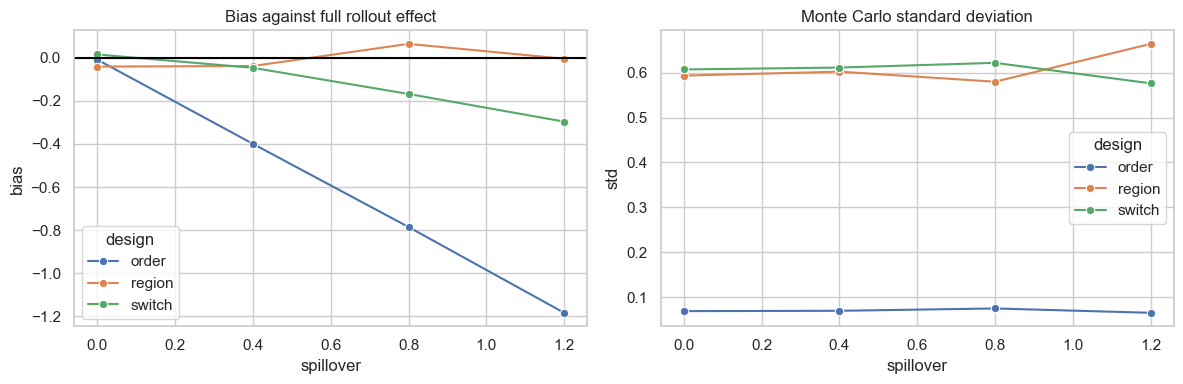

In [2]:
records=[]
for spill in [0,.4,.8,1.2]:
 for design in ['order','region','switch']:
  vals=np.array([simulate(design,spill,rng) for _ in range(250)])
  for v in vals:records.append((spill,design,v,direct+spill))
res=pd.DataFrame(records,columns=['spillover','design','estimate','target'])
agg=res.groupby(['spillover','design']).estimate.agg(['mean','std']).reset_index();agg['bias']=agg['mean']-(direct+agg.spillover)
print(agg.round(3))
fig,ax=plt.subplots(1,2,figsize=(12,4));sns.lineplot(data=agg,x='spillover',y='bias',hue='design',marker='o',ax=ax[0]);ax[0].axhline(0,color='black');ax[0].set_title('Bias against full rollout effect');sns.lineplot(data=agg,x='spillover',y='std',hue='design',marker='o',ax=ax[1]);ax[1].set_title('Monte Carlo standard deviation');plt.tight_layout();plt.show()

## 估计分布与设计选择

查看溢出强度为 0.8 时的模拟分布。此处区域设计仍有区域间干扰和小簇数风险；真实方案需依据司机跨区流动、供需时段和预期效应选择隔离边界。

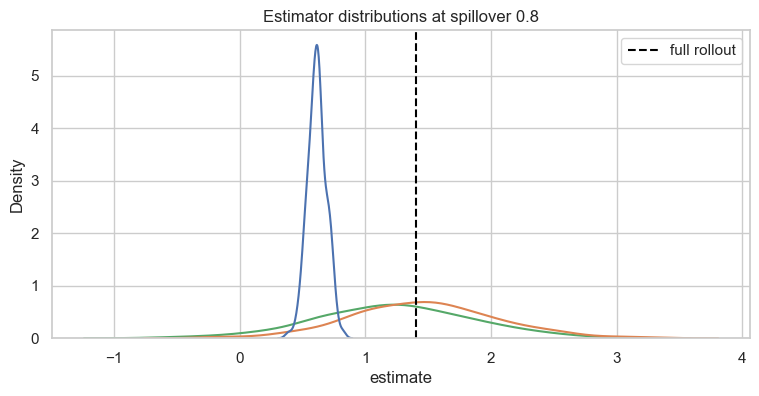

Decision: choose region randomization if supply is mostly local; use longer switch blocks when temporal carryover can be measured; pilot the design before launch.


In [3]:
s=res[res.spillover==.8]
plt.figure(figsize=(9,4));sns.kdeplot(data=s,x='estimate',hue='design',fill=False,common_norm=False);plt.axvline(1.4,color='black',ls='--',label='full rollout');plt.legend();plt.title('Estimator distributions at spillover 0.8');plt.show()
print('Decision: choose region randomization if supply is mostly local; use longer switch blocks when temporal carryover can be measured; pilot the design before launch.')

## 模拟结果解读与决策摘要

- 当溢出参数为 0.8 时，全量上线目标效应为 **1.4**。订单级分流的平均估计约 **0.615**，相对目标低约 **0.785**，因为两组共享区域供给。
- 区域级分流平均估计约 **1.464**，偏差较小，但 Monte Carlo 标准差约 **0.58**；订单级标准差仅约 **0.074**。降低污染会牺牲有效样本量。
- 示意性的时间切换设计平均估计约 **1.232**，仍受跨期残留影响。代码中的切换是简化暴露模型，不表示真实司机调度网络。
- 若司机跨区流动很强，区域级分流也无法充分隔离。真实设计需先画供需流动网络，再决定区域边界、切换周期及聚类推断方式。


## 实证分析接入

当前目录没有可用于此案例的真实数据，故不把模拟结论解释为实际业务结论。接入真实数据时：①取得脱敏且获授权的数据；②核对数据字典、随机化/触达机制和时间窗；③用真实数据替换模拟数据生成单元；④重跑质量诊断与敏感性分析；⑤在审阅关键识别假设后更新决策摘要。